# 05 Diferencias entre 2023 y 2024


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

RAIZ = Path.cwd().parent if Path.cwd().name == "01_notebooks" else Path.cwd()
GOLD = RAIZ / "02_datos" / "gold"
GRAFICOS = RAIZ / "04_graficos"
GRAFICOS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
AZUL, NARANJA, NARANJA_CLARO, GRIS = "#2a5d8f", "#c8742c", "#e3b98c", "#8a8a8a"

def guardar(fig, nombre, fuente):
    fig.text(0.01, 0.005, f"Fuente: {fuente}", fontsize=7.5, color=GRIS, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(GRAFICOS / nombre, dpi=160)
    plt.show()

anual = pd.read_csv(GOLD / "fact_decomiso_anual.csv", encoding="utf-8-sig")
dia = pd.read_csv(GOLD / "fact_decomiso_dia.csv", encoding="utf-8-sig", parse_dates=["fecha"])
pais = pd.read_csv(GOLD / "dim_pais.csv", encoding="utf-8-sig")
puertos = pd.read_csv(GOLD / "puertos_cocaina_ids.csv", encoding="utf-8-sig")
COCA = "Cocaína y derivados"
NOMBRE = dict(zip(pais["iso3"], pais["pais"]))
F71 = "UNODC, World Drug Report 2026, Annex 7.1"
FIDS = "UNODC IDS"

## La variación de 2024
Variación entre 2023 y 2024 de la cocaína en 7.1, en el panel de 30 países, separando el Mar del Norte (Bélgica, Países Bajos y Alemania) del resto.

In [2]:
panel = pais[pais.en_panel_cocaina][["iso3", "pais", "grupo_geografico"]]
c71 = anual[(anual.grupo_droga == COCA) & anual.anio.isin([2022, 2023, 2024])].merge(panel, on="iso3")
t71 = c71.pivot_table(index=["grupo_geografico", "pais"], columns="anio", values="kg", aggfunc="sum") / 1000
t71["variacion_2023_24"] = t71[2024] - t71[2023]

por_grupo = t71.groupby("grupo_geografico")[[2023, 2024, "variacion_2023_24"]].sum().round(1)
por_grupo.loc["Total panel"] = por_grupo.sum()
display(por_grupo)

mov = t71["variacion_2023_24"].droplevel(0).sort_values().round(1)
display(pd.concat([mov.head(5), mov.tail(3)]).to_frame("variacion_2023_24_t"))
assert round(por_grupo.loc["Mar del Norte", "variacion_2023_24"]) == -118
assert round(por_grupo.loc["Resto de Europa", "variacion_2023_24"]) == 37

anio,2023,2024,variacion_2023_24
grupo_geografico,,,
Mar del Norte,225.2,106.9,-118.3
Resto de Europa,222.1,258.9,36.8
Total panel,447.3,365.8,-81.5


,variacion_2023_24_t
pais,
Bélgica,-77.6
Países Bajos,-21.5
Alemania,-19.3
Italia,-8.8
Irlanda,-2.5
España,6.4
Reino Unido,9.7
Francia,30.3


## Dónde se puede usar IDS


In [3]:
PAISES = ["BEL", "NLD", "DEU", "FRA", "ESP"]
ids_anual = (dia[dia.grupo_droga == COCA].assign(anio=lambda x: x.fecha.dt.year)
             .groupby(["iso3", "anio"]).agg(ids_t=("kg", "sum"), dias=("fecha", "count"), decomisos=("n_decomisos", "sum")))
ids_anual["ids_t"] /= 1000
a71 = anual[anual.grupo_droga == COCA].set_index(["iso3", "anio"])["kg"] / 1000

indice = pd.MultiIndex.from_product([PAISES, [2022, 2023, 2024]], names=["iso3", "anio"])
cob = pd.DataFrame(index=indice).join(ids_anual).join(a71.rename("t_71")).fillna({"ids_t": 0, "dias": 0, "decomisos": 0})
cob["cobertura_pct"] = (cob.ids_t / cob.t_71 * 100).round(0)
cob = cob.reset_index()
cob["pais"] = cob.iso3.map(NOMBRE)
display(cob[["pais", "anio", "t_71", "ids_t", "cobertura_pct", "dias", "decomisos"]].round(1))

,pais,anio,t_71,ids_t,cobertura_pct,dias,decomisos
0,Bélgica,2022,110.9,33.9,31.0,78.0,101.0
1,Bélgica,2023,123.0,107.6,87.0,109.0,136.0
2,Bélgica,2024,45.5,44.6,98.0,150.0,207.0
3,Países Bajos,2022,51.4,0.0,0.0,0.0,0.0
4,Países Bajos,2023,59.1,0.0,0.0,0.0,0.0
5,Países Bajos,2024,37.6,0.0,0.0,0.0,0.0
6,Alemania,2022,20.0,10.4,52.0,19.0,20.0
7,Alemania,2023,43.1,5.8,13.0,23.0,25.0
8,Alemania,2024,23.8,9.4,40.0,25.0,28.0
9,Francia,2022,27.7,0.0,0.0,0.0,0.0


,cobertura_pct_2023,cobertura_pct_2024,decomisos_2023,decomisos_2024,meses_con_datos_de_186
pais,,,,,
Bélgica,87.0,98.0,136.0,207.0,116
Alemania,13.0,40.0,25.0,28.0,99
Países Bajos,0.0,0.0,0.0,0.0,22


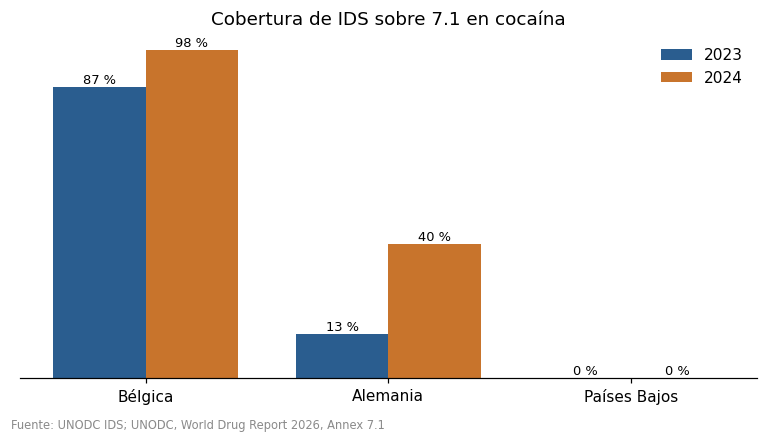

In [4]:
h31 = cob[cob.iso3.isin(["BEL", "DEU", "NLD"]) & cob.anio.isin([2023, 2024])].pivot(index="pais", columns="anio", values=["cobertura_pct", "decomisos"])
h31.columns = [f"{a}_{b}" for a, b in h31.columns]
h31["meses_con_datos_de_186"] = pais.set_index("pais").loc[h31.index, "ids_meses_con_datos"].astype(int)
h31 = h31.loc[["Bélgica", "Alemania", "Países Bajos"]]
display(h31)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
for k, (y, color) in enumerate([(2023, AZUL), (2024, NARANJA)]):
    v = h31[f"cobertura_pct_{y}"].values
    ax.bar(x + (k - 0.5) * 0.38, v, 0.38, color=color, label=str(y))
    for xi, vi in zip(x + (k - 0.5) * 0.38, v):
        ax.text(xi, vi + 1, f"{vi:.0f} %", ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(h31.index)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.legend(frameon=False)
ax.set_title("Cobertura de IDS sobre 7.1 en cocaína")
guardar(fig, "10_cobertura_ids_mar_del_norte.png", f"{FIDS}; {F71}")

## Tamaño de los decomisos en Bélgica
Se separan los días con más de una tonelada de cocaína del resto. 

In [5]:
UMBRAL_KG = 1000
bel = dia[(dia.iso3 == "BEL") & (dia.grupo_droga == COCA)].assign(anio=lambda x: x.fecha.dt.year)
bel = bel[bel.anio.isin([2023, 2024])].copy()
bel["clase"] = np.where(bel.kg > UMBRAL_KG, "Más de 1 t en el día", "1 t o menos en el día")

tam = (bel.groupby(["anio", "clase"]).agg(dias=("fecha", "count"), toneladas=("kg", lambda s: s.sum() / 1000)).round(1))
display(tam)

tot = bel.groupby("anio").kg.sum() / 1000
caida = tot[2023] - tot[2024]
grandes = bel[bel.kg > UMBRAL_KG].groupby("anio").kg.sum() / 1000
pequenos = bel[bel.kg <= UMBRAL_KG].groupby("anio").kg.sum() / 1000
print(f"Caída en IDS: {caida:.1f} t. Días con más de 1 t: {grandes[2023] - grandes[2024]:.1f} t. Resto de días: {pequenos[2023] - pequenos[2024]:.1f} t")
assert (bel[bel.anio == 2023].kg > UMBRAL_KG).sum() == 27 and (bel[bel.anio == 2024].kg > UMBRAL_KG).sum() == 13

dias  toneladas
anio clase                                 
2023 1 t o menos en el día    82       21.8
     Más de 1 t en el día     27       85.7
2024 1 t o menos en el día   137       17.5
     Más de 1 t en el día     13       27.1

Caída en IDS: 63.0 t. Días con más de 1 t: 58.6 t. Resto de días: 4.4 t


## Sensibilidad al umbral y días más grandes
Se repite la separación con otros umbrales y se miran los cinco días más grandes de cada año, para ver si la caída depende de uno o dos decomisos.

In [6]:
filas = []
for umbral in [500, 1000, 2000]:
    for y in [2023, 2024]:
        s = bel[bel.anio == y]
        g = s[s.kg > umbral]
        filas.append({"umbral_t": umbral / 1000, "anio": y, "dias_grandes": len(g),
                      "t_grandes": round(g.kg.sum() / 1000, 1), "t_resto": round(s[s.kg <= umbral].kg.sum() / 1000, 1)})
display(pd.DataFrame(filas))

top = {y: bel[bel.anio == y].nlargest(5, "kg").assign(t=lambda x: (x.kg / 1000).round(1))[["fecha", "t"]].reset_index(drop=True) for y in [2023, 2024]}
display(pd.concat(top, axis=1))

,umbral_t,anio,dias_grandes,t_grandes,t_resto
0,0.5,2023,47,100.5,7.0
1,0.5,2024,26,36.1,8.5
2,1.0,2023,27,85.7,21.8
3,1.0,2024,13,27.1,17.5
4,2.0,2023,13,66.0,41.6
5,2.0,2024,2,10.5,34.1


2023             2024     
       fecha     t      fecha    t
0 2023-10-17  11.2 2024-04-09  5.9
1 2023-11-03   7.8 2024-11-04  4.6
2 2023-10-15   7.7 2024-05-28  2.0
3 2023-10-23   7.0 2024-09-30  1.8
4 2023-07-16   6.8 2024-09-12  1.8

In [7]:
print(f"Caída en IDS: {caida:.1f} t. Días con más de 1 t: {grandes[2023] - grandes[2024]:.1f} t")
bel71 = a71[("BEL", 2023)] - a71[("BEL", 2024)]
norte71 = por_grupo.loc["Mar del Norte", "variacion_2023_24"] * -1
print(f"Bélgica en 7.1: {bel71:.1f} t de las {norte71:.1f} t que baja el Mar del Norte ({bel71 / norte71 * 100:.0f} %)")
mas2 = bel[bel.kg > 2000].groupby("anio").size()
print("Días con más de 2 t en IDS:", mas2.to_dict())

Caída en IDS: 63.0 t. Días con más de 1 t: 58.6 t
Bélgica en 7.1: 77.6 t de las 118.3 t que baja el Mar del Norte (66 %)
Días con más de 2 t en IDS: {2023: 13, 2024: 2}


## Posibles duplicados en IDS
El notebook 03 no borro los posibles duplicados: los cuento aparte. Se comprueba cuánto pesan en Bélgica.

In [8]:
dup = (dia[(dia.iso3 == "BEL") & (dia.grupo_droga == COCA)].assign(anio=lambda x: x.fecha.dt.year)
       .groupby("anio")[["kg", "kg_posibles_duplicados"]].sum().loc[2023:2024] / 1000).round(2)
dup["peso_pct"] = (dup.kg_posibles_duplicados / dup.kg * 100).round(1)
display(dup)

,kg,kg_posibles_duplicados,peso_pct
anio,,,
2023,107.59,1.21,1.1
2024,44.60,0.09,0.2


## Amberes en IDS y en EUDA
Amberes concentra casi todo lo que IDS recoge de Bélgica. 

In [9]:
EUDA_AMBERES = {2023: 121, 2024: 44}
amb = puertos[(puertos.iso3 == "BEL") & (puertos.puerto == "Antwerp") & puertos.anio.isin([2023, 2024])].set_index("anio")
comp = pd.DataFrame({"IDS_t": (amb.kg / 1000).round(1), "EUDA_t_aprox": pd.Series(EUDA_AMBERES)})
display(comp)

,IDS_t,EUDA_t_aprox
2023,102.1,121
2024,43.8,44


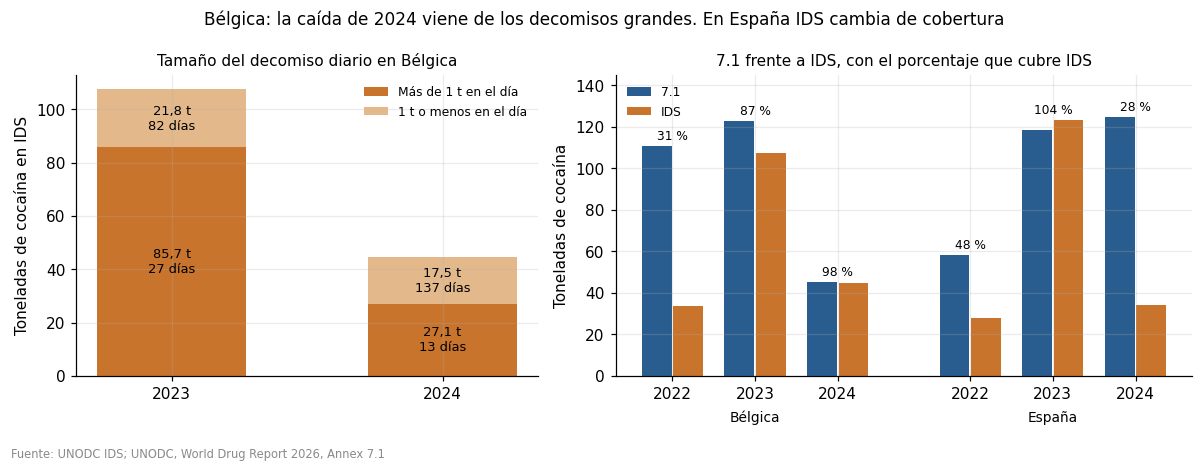

In [10]:
y = [2023, 2024]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
a = ax[0]
base = np.zeros(2)
for clase, color in [("Más de 1 t en el día", NARANJA), ("1 t o menos en el día", NARANJA_CLARO)]:
    v = np.array([tam.loc[(yy, clase), "toneladas"] for yy in y])
    d = np.array([tam.loc[(yy, clase), "dias"] for yy in y])
    a.bar([str(yy) for yy in y], v, bottom=base, color=color, width=0.55, label=clase)
    for i in range(2):
        a.text(i, base[i] + v[i] / 2, f"{v[i]:.1f} t\n{int(d[i])} días".replace(".", ","), ha="center", va="center", fontsize=8.5)
    base += v
a.set_ylabel("Toneladas de cocaína en IDS")
a.set_title("Tamaño del decomiso diario en Bélgica", fontsize=10)
a.legend(fontsize=8, loc="upper right", frameon=False)

b = ax[1]
x = np.arange(3)
for k, (iso, n) in enumerate([("BEL", "Bélgica"), ("ESP", "España")]):
    s = cob[cob.iso3 == iso].sort_values("anio")
    off = k * 3.6
    b.bar(x + off - 0.19, s.t_71, width=0.36, color=AZUL, label="7.1" if k == 0 else None)
    b.bar(x + off + 0.19, s.ids_t, width=0.36, color=NARANJA, label="IDS" if k == 0 else None)
    for xi, (t7, ti, cp) in zip(x + off, zip(s.t_71, s.ids_t, s.cobertura_pct)):
        b.text(xi, max(t7, ti) + 3, f"{int(cp)} %", ha="center", fontsize=8)
    b.text(off + 1, -22, n, ha="center", fontsize=9)
b.set_xticks(np.concatenate([x, x + 3.6]))
b.set_xticklabels([2022, 2023, 2024] * 2)
b.set_ylim(-0, 145)
b.set_ylabel("Toneladas de cocaína")
b.set_title("7.1 frente a IDS, con el porcentaje que cubre IDS", fontsize=10)
b.legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Bélgica: la caída de 2024 viene de los decomisos grandes. En España IDS cambia de cobertura", fontsize=11)
guardar(fig, "07_belgica_tamano_decomisos.png", f"{FIDS}; {F71}")

## Cifras externas con su fuente
Cifras que no salen de los datos del proyecto. Se dejan con su fuente para poder citarlas.

In [11]:
EXTERNAS = pd.DataFrame([
    {"cifra": "Hallazgos de más de 2 t en Bélgica, 2023 y 2024", "valor": "13 y 2", "fuente": "AFP (9/1/2025), con datos de la aduana belga; el recuento de >2 t es propio con IDS", "enlace": "https://www.swissinfo.ch/spa/los-decomisos-de-coca%C3%ADna-en-el-puerto-de-amberes-se-reducen-m%C3%A1s-de-la-mitad-por-los-controles-reforzados-en-am%C3%A9rica-latina/88697822"},
    {"cifra": "Toneladas interceptadas en origen con destino a Bélgica, 2023 y 2024", "valor": "45 y 81", "fuente": "AFP (9/1/2025): 81,4 t frente a 45 t en puertos latinoamericanos con destino a Amberes", "enlace": "https://www.swissinfo.ch/spa/los-decomisos-de-coca%C3%ADna-en-el-puerto-de-amberes-se-reducen-m%C3%A1s-de-la-mitad-por-los-controles-reforzados-en-am%C3%A9rica-latina/88697822"},
    {"cifra": "Posible efecto waterbed", "valor": "Cualitativo", "fuente": "Brombacher, Fares y Scaturro (17/11/2025), Global Initiative", "enlace": "https://globalinitiative.net/analysis/what-the-declining-amount-of-cocaine-seized-in-western-europe-doesnt-tell-us/"},
    {"cifra": "Mayores puertos de la UE por mercancías, 2024", "valor": "Róterdam, Amberes-Brujas y Hamburgo", "fuente": "Eurostat, Maritime transport of goods, annual data", "enlace": "https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Maritime_transport_of_goods_-_annual_data"},
])
display(EXTERNAS)

,cifra,valor,fuente,enlace
0,"Hallazgos de más de 2 t en Bélgica, 2023 y 2024",13 y 2,"AFP (9/1/2025), con datos de la aduana belga; ...",https://www.swissinfo.ch/spa/los-decomisos-de-...
1,Toneladas interceptadas en origen con destino ...,45 y 81,"AFP (9/1/2025): 81,4 t frente a 45 t en puerto...",https://www.swissinfo.ch/spa/los-decomisos-de-...
2,Posible efecto waterbed,Cualitativo,"Brombacher, Fares y Scaturro (17/11/2025), Glo...",https://globalinitiative.net/analysis/what-the...
3,"Mayores puertos de la UE por mercancías, 2024","Róterdam, Amberes-Brujas y Hamburgo","Eurostat, Maritime transport of goods, annual ...",https://ec.europa.eu/eurostat/statistics-expla...


## Resumen de cifras para el informe

In [12]:
resumen = {
    "Variación Mar del Norte 2023-24 (t)": round(por_grupo.loc["Mar del Norte", "variacion_2023_24"], 1),
    "Variación resto del panel 2023-24 (t)": round(por_grupo.loc["Resto de Europa", "variacion_2023_24"], 1),
    "Variación total del panel 2023-24 (t)": round(por_grupo.loc["Total panel", "variacion_2023_24"], 1),
    "Bélgica, cobertura IDS sobre 7.1 en 2023 (%)": float(cob[(cob.iso3 == "BEL") & (cob.anio == 2023)].cobertura_pct.iloc[0]),
    "Bélgica, cobertura IDS sobre 7.1 en 2024 (%)": float(cob[(cob.iso3 == "BEL") & (cob.anio == 2024)].cobertura_pct.iloc[0]),
    "Bélgica, días con más de 1 t en 2023": int((bel[bel.anio == 2023].kg > UMBRAL_KG).sum()),
    "Bélgica, días con más de 1 t en 2024": int((bel[bel.anio == 2024].kg > UMBRAL_KG).sum()),
    "Bélgica, caída en IDS (t)": round(caida, 1),
    "Bélgica, parte de la caída en días con más de 1 t (t)": round(grandes[2023] - grandes[2024], 1),
}
display(pd.Series(resumen, name="valor").to_frame())

,valor
Variación Mar del Norte 2023-24 (t),-118.3
Variación resto del panel 2023-24 (t),36.8
Variación total del panel 2023-24 (t),-81.5
"Bélgica, cobertura IDS sobre 7.1 en 2023 (%)",87.0
"Bélgica, cobertura IDS sobre 7.1 en 2024 (%)",98.0
"Bélgica, días con más de 1 t en 2023",27.0
"Bélgica, días con más de 1 t en 2024",13.0
"Bélgica, caída en IDS (t)",63.0
"Bélgica, parte de la caída en días con más de 1 t (t)",58.6
